<a href="https://colab.research.google.com/github/Iqmaa/Humanoid-RL/blob/main/Humanoid_mjx_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Humanoid on GPU (jax)

In [4]:
!nvidia-smi

Sun Nov  8 22:30:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
!pip -q install mujoco mujoco-mjx brax mediapy

In [6]:
import os, glob, shutil, zipfile
from google.colab import files

if not os.path.exists("robot/humanoid2.xml"):
    print("Click 'Choose files' below, select robot.zip, and wait until it shows 100%.")
    up = files.upload()
    assert up, "Nothing was uploaded: run the cell again and pick robot.zip"
    name = list(up)[0]
    assert name.endswith(".zip"), f"Please upload the zip, not {name}"
    zipfile.ZipFile(name).extractall("robot")

# if the zip had an extra folder inside, move the contents up one level
xmls = glob.glob("robot/**/humanoid2.xml", recursive=True)
assert xmls, "humanoid2.xml is not in the zip: re-zip from inside the folder that contains it"
folder = os.path.dirname(xmls[0])
if folder != "robot":
    for item in os.listdir(folder):
        shutil.move(os.path.join(folder, item), os.path.join("robot", item))

print("robot/ contains:", sorted(os.listdir("robot")))
assert os.path.isdir("robot/meshes"), "robot/meshes is missing: the zip needs the meshes folder next to the XML"

Click 'Choose files' below, select robot.zip, and wait until it shows 100%.


Saving robot.zip to robot.zip
robot/ contains: ['humanoid2.xml', 'meshes']


In [7]:
%%writefile mjx_humanoid_env.py
"""Your humanoid as a Brax-trainable MJX environment (shared by the training and render cells)."""
import functools
import os

import jax
import jax.numpy as jnp
import mujoco
from mujoco import mjx
from brax.envs import base
from brax.training.agents.ppo import networks as ppo_networks
from brax.training.acme import running_statistics

XML = os.path.abspath(os.environ["HUMANOID_XML"])   # set by the notebook before importing

# ---- same task definition as the SB3 version (Humanoid-v5 + your two wrappers) ----------
N_SUBSTEPS = 5               # frame_skip=5  -> dt = 5 * timestep(0.003) = 0.015 s
Z_RANGE = (0.33, 0.70)       # healthy root height
MIN_UP = 0.85                # pelvis tilt limit (1.0 = upright)
W_FORWARD, W_HEALTHY, W_CTRL, W_HEADING = 1.25, 5.0, 0.1, 2.0
RESET_NOISE = 1e-2

mj_model = mujoco.MjModel.from_xml_path(XML)
mx_model = mjx.put_model(mj_model, impl="jax")
DT = float(mj_model.opt.timestep) * N_SUBSTEPS
CTRL_HI = jnp.asarray(mj_model.actuator_ctrlrange[:, 1])    # 0.4 for every motor
ACTION_SIZE = mj_model.nu
OBS_SIZE = (mj_model.nq - 2) + mj_model.nv                  # qpos[2:], qvel


def observation(data):
    return jnp.concatenate([data.qpos[2:], data.qvel])


def core_reset(rng):
    k1, k2 = jax.random.split(rng)
    data = mjx.make_data(mj_model, impl="jax")
    n = mj_model.nq - 7
    qpos = data.qpos.at[7:].add(jax.random.uniform(k1, (n,), minval=-RESET_NOISE, maxval=RESET_NOISE))
    qvel = jax.random.uniform(k2, (mj_model.nv,), minval=-RESET_NOISE, maxval=RESET_NOISE)
    data = mjx.forward(mx_model, data.replace(qpos=qpos, qvel=qvel))
    return data, observation(data)


def core_step(data, action):
    ctrl = jnp.clip(action, -1.0, 1.0) * CTRL_HI            # Brax's tanh policy -> [-1, 1]
    com_before = data.subtree_com[1]
    data = data.replace(ctrl=ctrl)
    data = jax.lax.fori_loop(0, N_SUBSTEPS, lambda _, d: mjx.step(mx_model, d), data)

    vx = (data.subtree_com[1, 0] - com_before[0]) / DT      # forward = +x
    z = data.qpos[2]
    up = data.xmat[1, 2, 2]                                 # 1.0 = upright
    fwd_y = -data.xmat[1, 1, 1]                             # sideways component of facing direction

    healthy = (z > Z_RANGE[0]) & (z < Z_RANGE[1]) & (up > MIN_UP)
    reward = (W_FORWARD * vx + W_HEALTHY * healthy
              - W_CTRL * jnp.sum(jnp.square(ctrl)) - W_HEADING * fwd_y ** 2)
    done = 1.0 - healthy.astype(jnp.float32)
    return data, observation(data), reward, done, {"x_velocity": vx, "heading_y": fwd_y}


class HumanoidEnv(base.Env):
    def reset(self, rng):
        data, obs = core_reset(rng)
        zero = jnp.zeros(())
        return base.State(pipeline_state=data, obs=obs, reward=zero, done=zero,
                          metrics={"x_velocity": zero, "heading_y": zero}, info={})

    def step(self, state, action):
        data, obs, reward, done, new_metrics = core_step(state.pipeline_state, action)
        metrics = {**state.metrics, **new_metrics}      # Brax's wrappers add their own keys; keep them
        return state.replace(pipeline_state=data, obs=obs, reward=reward, done=done, metrics=metrics)

    @property
    def observation_size(self):
        return OBS_SIZE

    @property
    def action_size(self):
        return ACTION_SIZE

    @property
    def backend(self):
        return "mjx"


# Policy / value network sizes. Training and rendering MUST use the same factory.
make_networks = functools.partial(
    ppo_networks.make_ppo_networks,
    policy_hidden_layer_sizes=(256, 256), value_hidden_layer_sizes=(256, 256))


def make_policy(params, deterministic=True):
    nets = make_networks(OBS_SIZE, ACTION_SIZE, preprocess_observations_fn=running_statistics.normalize)
    return ppo_networks.make_inference_fn(nets)(params, deterministic=deterministic)

Writing mjx_humanoid_env.py


In [13]:
%%writefile jax_compat.py
import jax, jax.numpy as jnp

def apply():
    """Brax and Flax call internals that newer JAX removed. Shim them only if they are missing."""
    shims = []

    # 1. Shim device_put_replicated
    try:
        jax.device_put_replicated
    except AttributeError:
        def device_put_replicated(x, devices):
            n = len(devices)
            stacked = jax.tree.map(lambda a: jnp.stack([jnp.asarray(a)] * n), x)
            return jax.pmap(lambda t: t, devices=list(devices))(stacked)
        jax.device_put_replicated = device_put_replicated
        shims.append("jax.device_put_replicated")

    # 2. Shim get_opaque_trace_state
    try:
        jax.core.get_opaque_trace_state
    except AttributeError:
        try:
            import jax.extend.core as jec
            jax.core.get_opaque_trace_state = jec.get_opaque_trace_state
            shims.append("jax.core.get_opaque_trace_state")
        except (ImportError, AttributeError):
            # Fallback to no-op trace state if jax.extend isn't populated
            jax.core.get_opaque_trace_state = lambda convention=None: float('-inf')
            shims.append("jax.core.get_opaque_trace_state (fallback)")

    return f"Shimmed: {', '.join(shims)}" if shims else "No shims needed"

Overwriting jax_compat.py


In [14]:
import xml.etree.ElementTree as ET
import numpy as np
import mujoco

def make_fast_collision_xml(src, dst):
    """Meshes stay (visual + mass), but only two simple foot BOXES collide with the floor."""
    m = mujoco.MjModel.from_xml_path(src)
    d = mujoco.MjData(m); mujoco.mj_forward(m, d)
    tree = ET.parse(src); root = tree.getroot()
    for g in root.iter("geom"):                       # meshes: no collisions any more
        if g.get("mesh"):
            g.set("contype", "0"); g.set("conaffinity", "0")
    for side in ("left", "right"):
        gid = next(i for i in range(m.ngeom)
                   if mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_MESH, m.geom_dataid[i]) == f"{side}_foot")
        mid, bid = m.geom_dataid[gid], m.geom_bodyid[gid]
        v = m.mesh_vert[m.mesh_vertadr[mid]: m.mesh_vertadr[mid] + m.mesh_vertnum[mid]]
        w = d.geom_xpos[gid] + v @ d.geom_xmat[gid].reshape(3, 3).T          # foot hull, world frame
        lo, hi = w.min(0), w.max(0)
        R = d.xmat[bid].reshape(3, 3)
        centre = R.T @ ((lo + hi) / 2 - d.xpos[bid])                         # box centre in the body frame
        half = np.abs(R.T) @ ((hi - lo) / 2)                                 # half sizes in the body frame
        body = root.find(f".//body[@name='{mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_BODY, bid)}']")
        ET.SubElement(body, "geom", name=f"{side}_foot_box", type="box",
                      pos=" ".join(f"{x:.5f}" for x in centre), size=" ".join(f"{x:.5f}" for x in half),
                      contype="0", conaffinity="1", condim="3", friction="1 0.005 0.0001",
                      density="0", group="3", rgba="0.1 0.9 0.1 0.25")                  # density 0: adds no mass
        print(f"{side} foot box: {2*half[0]*100:.1f} x {2*half[1]*100:.1f} x {2*half[2]*100:.1f} cm (body frame)")
    ET.indent(tree, space="  "); tree.write(dst, encoding="unicode")

make_fast_collision_xml("robot/humanoid2.xml", "robot/humanoid_fast.xml")

left foot box: 8.0 x 13.0 x 6.2 cm (body frame)
right foot box: 8.0 x 13.0 x 6.2 cm (body frame)


In [15]:
import os, functools
os.environ["HUMANOID_XML"] = "robot/humanoid_fast.xml"    # or "robot/humanoid2.xml" (slower mesh collisions)
from datetime import datetime
import jax
import matplotlib.pyplot as plt
from IPython.display import clear_output

import jax_compat; print(jax_compat.apply())
from brax.training.agents.ppo import train as ppo
from brax.io import model
import mjx_humanoid_env as E

print("JAX", jax.__version__, "| backend:", jax.default_backend(), "|", jax.devices())
assert jax.default_backend() != "cpu", "No GPU found: Runtime -> Change runtime type -> GPU"
print("obs size", E.OBS_SIZE, "| actions", E.ACTION_SIZE, "| control dt", E.DT)

# Checkpoints + final params go here. Drive survives a disconnected session; set USE_DRIVE=False to skip.
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/humanoid_mjx"
else:
    SAVE_DIR = "/content/humanoid_mjx"
os.makedirs(SAVE_DIR, exist_ok=True)
print("saving to", SAVE_DIR)

not needed (this JAX still has device_put_replicated)
JAX 0.11.1 | backend: gpu | [CudaDevice(id=0)]
obs size 43 | actions 16 | control dt 0.015
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saving to /content/drive/MyDrive/humanoid_mjx


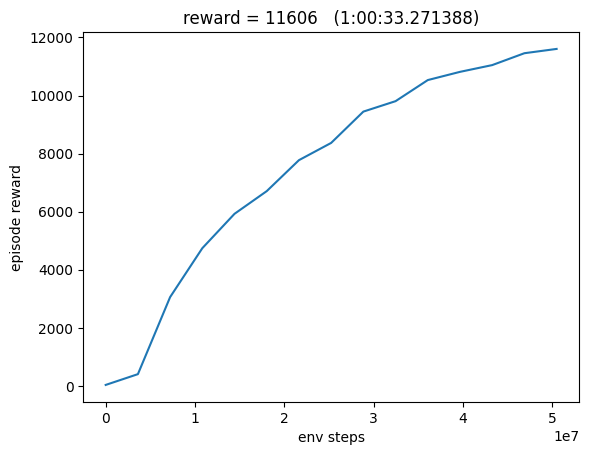

Trained in 1:00:34.884540
saved -> /content/drive/MyDrive/humanoid_mjx/humanoid_params


In [18]:
import jax_compat, importlib
importlib.reload(jax_compat)
print(jax_compat.apply())

env = E.HumanoidEnv()
xdata, ydata = [], []
t0 = datetime.now()

def progress(num_steps, metrics):
    xdata.append(num_steps); ydata.append(float(metrics["eval/episode_reward"]))
    clear_output(wait=True)
    plt.xlabel("env steps"); plt.ylabel("episode reward")
    plt.title(f"reward = {ydata[-1]:.0f}   ({datetime.now() - t0})")
    plt.plot(xdata, ydata); plt.show()

def save_checkpoint(step, make_policy, params):
    model.save_params(f"{SAVE_DIR}/params_{step}", params)

train_fn = functools.partial(
    ppo.train,
    num_timesteps=50_000_000, num_evals=15, reward_scaling=0.1,
    episode_length=1000, normalize_observations=True, action_repeat=1,
    unroll_length=10, num_minibatches=32, num_updates_per_batch=8,
    discounting=0.97, learning_rate=3e-4, entropy_cost=1e-3,
    num_envs=2048, batch_size=1024, seed=0,
    network_factory=E.make_networks,
)
make_inference_fn, params, _ = train_fn(environment=env, progress_fn=progress, policy_params_fn=save_checkpoint)
print("Trained in", datetime.now() - t0)

model.save_params(f"{SAVE_DIR}/humanoid_params", params)
print("saved ->", f"{SAVE_DIR}/humanoid_params")

In [2]:
import os
os.environ["MUJOCO_GL"] = "egl"          # headless rendering (before any mujoco import)
os.environ["JAX_PLATFORMS"] = "cpu"      # the rollout is small; skip the GPU
os.environ["HUMANOID_XML"] = "robot/humanoid_fast.xml"
USE_DRIVE = True                          # same setting as in the training cell
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/humanoid_mjx"
else:
    SAVE_DIR = "/content/humanoid_mjx"
PARAMS = f"{SAVE_DIR}/humanoid_params"    # or e.g. f"{SAVE_DIR}/params_30000000" for a checkpoint
N_STEPS = 500                              # 500 steps ~ 7.5 s of robot time

# Apply the JAX/Flax compatibility shim before running anything else
import jax_compat
jax_compat.apply()

import jax, numpy as np, mujoco, mediapy as media
from brax.io import model
import mjx_humanoid_env as E

policy = jax.jit(E.make_policy(model.load_params(PARAMS), deterministic=True))
env = E.HumanoidEnv(); reset, step = jax.jit(env.reset), jax.jit(env.step)

state = reset(jax.random.PRNGKey(0))
qpos, vx, side = [np.asarray(state.pipeline_state.qpos)], [], []
for i in range(N_STEPS):
    action, _ = policy(state.obs, jax.random.PRNGKey(i))
    state = step(state, action)
    qpos.append(np.asarray(state.pipeline_state.qpos))
    vx.append(float(state.metrics["x_velocity"])); side.append(float(state.metrics["heading_y"]))
    if float(state.done) > 0:
        print(f"episode ended (fell / tilted) at step {i + 1} of {N_STEPS}"); break
else:
    print(f"stayed up for all {N_STEPS} steps")
print(f"mean forward speed {np.mean(vx):+.2f} m/s | final heading {np.degrees(np.arcsin(np.clip(side[-1], -1, 1))):+.0f} deg "
      f"(0 = straight, + = turned left)")

# replay in plain MuJoCo and render
m = mujoco.MjModel.from_xml_path(os.environ["HUMANOID_XML"]); d = mujoco.MjData(m)

# Fallback mechanism if EGL loading fails due to previous imports
try:
    renderer = mujoco.Renderer(m, 480, 640)
except Exception as e:
    print("EGL renderer failed, trying OSMesa fallback...")
    os.environ["MUJOCO_GL"] = "osmesa"
    import importlib
    importlib.reload(mujoco)
    renderer = mujoco.Renderer(m, 480, 640)

cam = mujoco.MjvCamera(); cam.type = mujoco.mjtCamera.mjCAMERA_TRACKING
cam.trackbodyid = 1; cam.distance = 2.2; cam.azimuth = 120; cam.elevation = -15
frames = []
for q in qpos:
    d.qpos[:] = q; mujoco.mj_forward(m, d)
    renderer.update_scene(d, camera=cam); frames.append(renderer.render())
fps = int(round(1.0 / E.DT))
media.write_video("humanoid_mjx.mp4", frames, fps=fps)
media.show_video(frames, fps=fps)
try:
    from google.colab import files
    files.download("humanoid_mjx.mp4")
except Exception as e:
    print("download skipped (grab it from the Files panel):", e)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
stayed up for all 500 steps
mean forward speed +5.14 m/s | final heading +14 deg (0 = straight, + = turned left)


This browser does not support the video tag.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>